# Seoul Bike Sharing Demand Prediction - Regression Track

## Capstone Project - Review 1

**Objective:** Predict the hourly count of rented bikes in Seoul based on weather, environmental, and calendar features.

* **Reproducibility:** Global `random_state=42` is strictly enforced across all splits, cross-validation folds, and stochastic estimators.
* **Data Leakage Prevention:** All transformations, scalers, and encoders are strictly fitted on the training split only.
* **Evaluation Metrics:** Evaluated across $R^2$ Score (Train and Test), Root Mean Squared Error (RMSE), and Mean Absolute Error (MAE).

### Environment Configuration & Core Imports
This cell loads the necessary libraries for data analysis (`pandas`, `numpy`), visualization (`matplotlib`, `seaborn`), and scikit-learn modules. It sets up plot styling, a dynamic data path resolver, and configures the global random seed (`42`) for full reproducibility.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import os
warnings.filterwarnings('ignore')

# Set LOKY_MAX_CPU_COUNT to prevent Windows joblib wmic core-detection warning
os.environ.setdefault('LOKY_MAX_CPU_COUNT', str(os.cpu_count() or 4))

# Reproducibility seed
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

def get_data_path(rel_path):
    candidates = [
        rel_path,
        os.path.join('..', rel_path) if not rel_path.startswith('..') else rel_path,
        os.path.join('../..', rel_path.lstrip('./\\')),
        os.path.join('data', os.path.basename(rel_path)),
        os.path.join('../data', os.path.basename(rel_path)),
        os.path.join('../../data', os.path.basename(rel_path)),
    ]
    for p in candidates:
        if os.path.exists(p):
            return p
    return rel_path

print("Regression notebook initialized. Random state set to 42.")

Regression notebook initialized. Random state set to 42.


## Phase 2: Exploratory Data Analysis (EDA)

In this phase, we perform an exhaustive audit of the Seoul Bike Sharing dataset:
1. **Data Ingestion & Integrity Audit:** Clean headers, inspect data types, detect missing values.
2. **Target Variable Analysis (`rented_bike_count`):** Distribution shape, skewness, zero-demand hours.
3. **Temporal & Seasonal Patterns:** Hourly peak commuter trends, day/night cycles, and seasonal shifts.
4. **Environmental & Weather Dynamics:** Correlation with temperature, humidity, solar radiation, and rainfall.
5. **Multicollinearity Screening:** Feature-to-feature correlation analysis.

### Step 1: Load Dataset & Standardize Column Headers
Load the Seoul Bike Sharing dataset from `data/SeoulBikeData.csv` using unicode-escape encoding to handle special degree symbols. 
Standardize column names to `snake_case` without special characters for consistency.

In [2]:
raw_bike_df = pd.read_csv(get_data_path('data/SeoulBikeData.csv'), encoding='unicode_escape')

# Clean column names to standard lower_snake_case without special characters
bike_df = raw_bike_df.copy()
bike_df.columns = [
    'date',
    'rented_bike_count',
    'hour',
    'temperature',
    'humidity',
    'wind_speed',
    'visibility',
    'dew_point_temperature',
    'solar_radiation',
    'rainfall',
    'snowfall',
    'seasons',
    'holiday',
    'functioning_day'
]

print(f"Dataset Shape: {bike_df.shape[0]} rows, {bike_df.shape[1]} columns")
bike_df.head()

Dataset Shape: 8760 rows, 14 columns


,date,rented_bike_count,hour,temperature,humidity,wind_speed,visibility,dew_point_temperature,solar_radiation,rainfall,snowfall,seasons,holiday,functioning_day
0,01/12/2017,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
1,01/12/2017,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2,01/12/2017,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes
3,01/12/2017,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
4,01/12/2017,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes


### Step 2: Data Integrity & Completeness Audit
Inspect column schemas, data types, check for missing values, and calculate summary statistics for all numerical features.

In [3]:
print("=== Column Schema & Data Types ===")
print(bike_df.info())

print("\n=== Missing Values Check ===")
missing_counts = bike_df.isnull().sum()
print(missing_counts[missing_counts > 0] if missing_counts.sum() > 0 else "No missing values found across all columns.")

print("\n=== Statistical Summary (Numerical Features) ===")
bike_df.describe().T

=== Column Schema & Data Types ===
<class 'pandas.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   date                   8760 non-null   str    
 1   rented_bike_count      8760 non-null   int64  
 2   hour                   8760 non-null   int64  
 3   temperature            8760 non-null   float64
 4   humidity               8760 non-null   int64  
 5   wind_speed             8760 non-null   float64
 6   visibility             8760 non-null   int64  
 7   dew_point_temperature  8760 non-null   float64
 8   solar_radiation        8760 non-null   float64
 9   rainfall               8760 non-null   float64
 10  snowfall               8760 non-null   float64
 11  seasons                8760 non-null   str    
 12  holiday                8760 non-null   str    
 13  functioning_day        8760 non-null   str    
dtypes: float64(6), int64(4), str(4)


,count,mean,std,min,25%,50%,75%,max
rented_bike_count,8760.0,704.602055,644.997468,0.0,191.00,504.50,1065.25,3556.00
hour,8760.0,11.500000,6.922582,0.0,5.75,11.50,17.25,23.00
temperature,8760.0,12.882922,11.944825,-17.8,3.50,13.70,22.50,39.40
humidity,8760.0,58.226256,20.362413,0.0,42.00,57.00,74.00,98.00
wind_speed,8760.0,1.724909,1.036300,0.0,0.90,1.50,2.30,7.40
visibility,8760.0,1436.825799,608.298712,27.0,940.00,1698.00,2000.00,2000.00
dew_point_temperature,8760.0,4.073813,13.060369,-30.6,-4.70,5.10,14.80,27.20
solar_radiation,8760.0,0.569111,0.868746,0.0,0.00,0.01,0.93,3.52
rainfall,8760.0,0.148687,1.128193,0.0,0.00,0.00,0.00,35.00
snowfall,8760.0,0.075068,0.436746,0.0,0.00,0.00,0.00,8.80


### Step 3: Categorical Variables Audit
Examine the unique categories and distribution of values across categorical attributes: `seasons`, `holiday`, and `functioning_day`.

In [4]:
cat_cols = ['seasons', 'holiday', 'functioning_day']
for col in cat_cols:
    print(f"--- Value Counts: {col} ---")
    print(bike_df[col].value_counts())
    print()

--- Value Counts: seasons ---
seasons
Spring    2208
Summer    2208
Autumn    2184
Winter    2160
Name: count, dtype: int64

--- Value Counts: holiday ---
holiday
No Holiday    8328
Holiday        432
Name: count, dtype: int64

--- Value Counts: functioning_day ---
functioning_day
Yes    8465
No      295
Name: count, dtype: int64



### Step 4: Target Variable Distribution (`rented_bike_count`)
Analyze the distribution of hourly bike rentals via Histogram with Kernel Density Estimation (KDE) and a Boxplot to check skewness, outliers, and zero-rental concentrations.

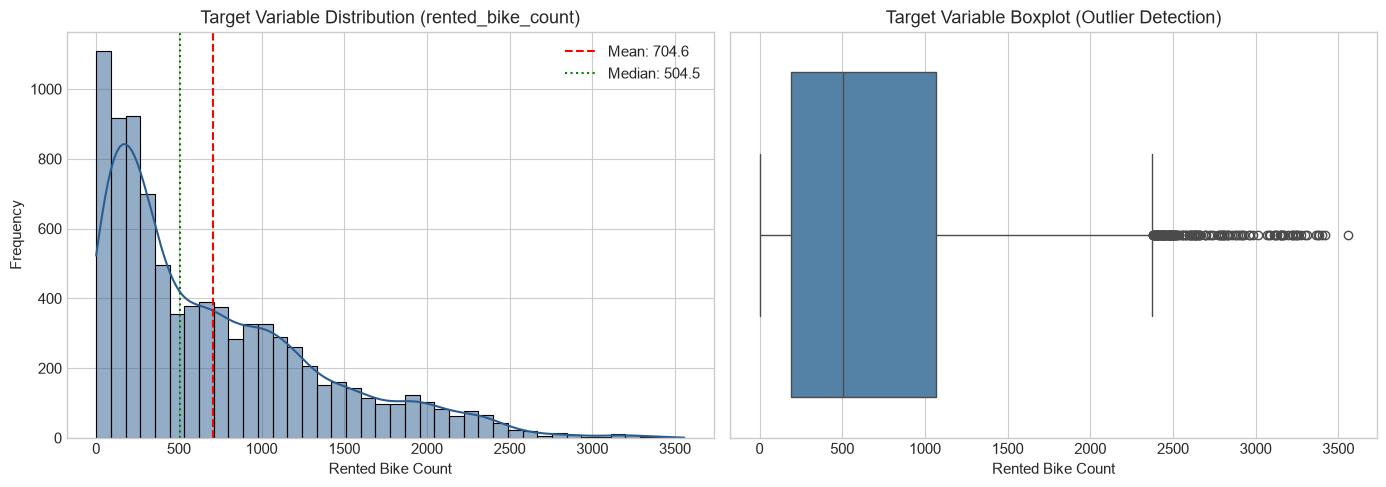

Skewness: 1.153
Kurtosis: 0.853
Zero Demand Hours: 295 (3.37%)


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram & KDE
sns.histplot(bike_df['rented_bike_count'], kde=True, ax=axes[0], color='#2b5c8f', bins=40)
axes[0].axvline(bike_df['rented_bike_count'].mean(), color='red', linestyle='--', label=f"Mean: {bike_df['rented_bike_count'].mean():.1f}")
axes[0].axvline(bike_df['rented_bike_count'].median(), color='green', linestyle=':', label=f"Median: {bike_df['rented_bike_count'].median():.1f}")
axes[0].set_title('Target Variable Distribution (rented_bike_count)')
axes[0].set_xlabel('Rented Bike Count')
axes[0].set_ylabel('Frequency')
axes[0].legend()

# Boxplot
sns.boxplot(x=bike_df['rented_bike_count'], ax=axes[1], color='#4682b4')
axes[1].set_title('Target Variable Boxplot (Outlier Detection)')
axes[1].set_xlabel('Rented Bike Count')

plt.tight_layout()
plt.show()

print(f"Skewness: {bike_df['rented_bike_count'].skew():.3f}")
print(f"Kurtosis: {bike_df['rented_bike_count'].kurt():.3f}")
print(f"Zero Demand Hours: {(bike_df['rented_bike_count'] == 0).sum()} ({(bike_df['rented_bike_count'] == 0).mean()*100:.2f}%)")

### Step 5: Temporal Dynamics - Hourly Rental Patterns
Visualize the average rental volume across the 24 hours of the day to identify commuter peak hours and diurnal patterns.

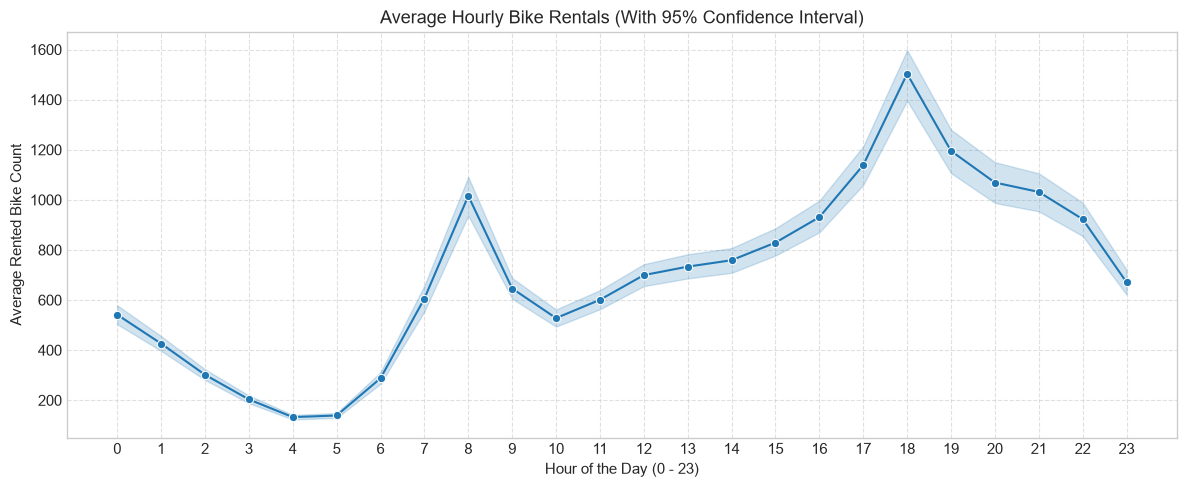

In [6]:
fig, ax = plt.subplots(figsize=(12, 5))
sns.lineplot(data=bike_df, x='hour', y='rented_bike_count', errorbar=('ci', 95), ax=ax, color='#1f77b4', marker='o')
ax.set_title('Average Hourly Bike Rentals (With 95% Confidence Interval)')
ax.set_xlabel('Hour of the Day (0 - 23)')
ax.set_ylabel('Average Rented Bike Count')
ax.set_xticks(range(0, 24))
ax.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

### Step 6: Seasonal & Calendar Variations
Investigate how bike rental demand changes across seasons (`Winter`, `Spring`, `Summer`, `Autumn`), official holidays, and functioning status.

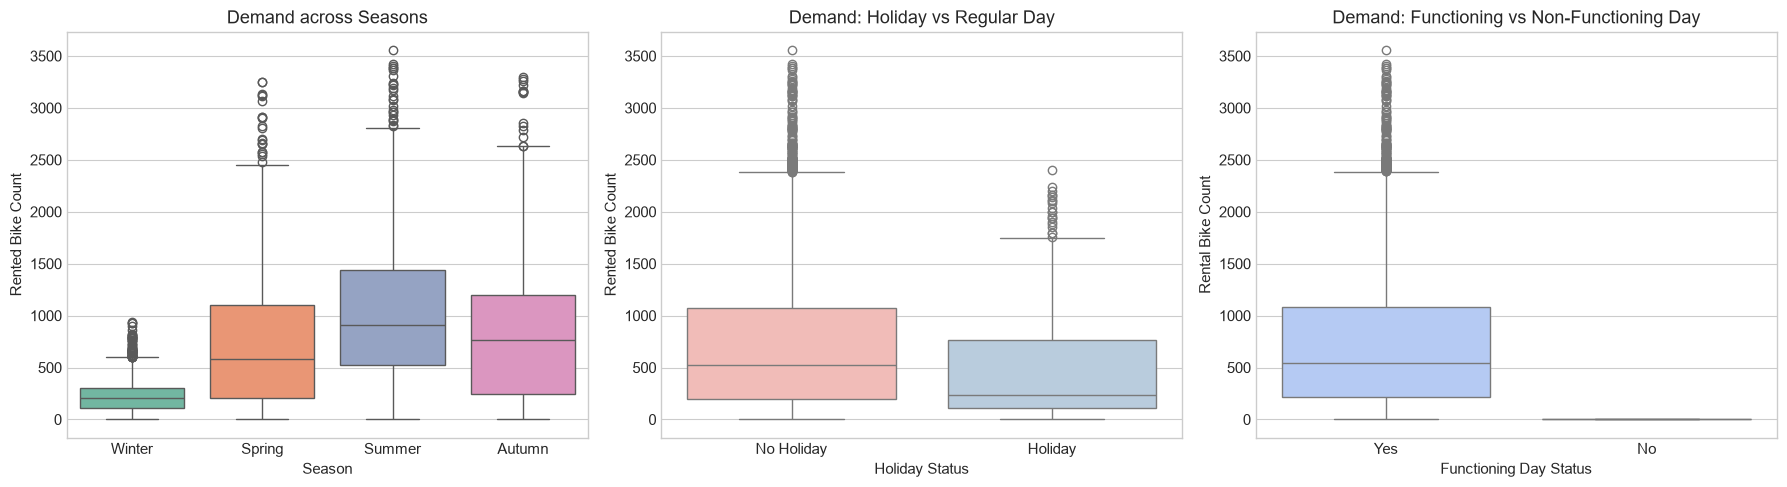

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Rentals across Seasons
sns.boxplot(data=bike_df, x='seasons', y='rented_bike_count', ax=axes[0], palette='Set2')
axes[0].set_title('Demand across Seasons')
axes[0].set_xlabel('Season')
axes[0].set_ylabel('Rented Bike Count')

# Holiday vs Non-Holiday
sns.boxplot(data=bike_df, x='holiday', y='rented_bike_count', ax=axes[1], palette='Pastel1')
axes[1].set_title('Demand: Holiday vs Regular Day')
axes[1].set_xlabel('Holiday Status')
axes[1].set_ylabel('Rented Bike Count')

# Functioning Day Status
sns.boxplot(data=bike_df, x='functioning_day', y='rented_bike_count', ax=axes[2], palette='coolwarm')
axes[2].set_title('Demand: Functioning vs Non-Functioning Day')
axes[2].set_xlabel('Functioning Day Status')
axes[2].set_ylabel('Rental Bike Count')

plt.tight_layout()
plt.show()

### Step 7: Weather & Environmental Relationships
Scatter plots with degree-2 polynomial regression trend lines illustrating the impact of key meteorological variables (`temperature`, `humidity`, `wind_speed`, `solar_radiation`, `rainfall`, `snowfall`) on bike demand.

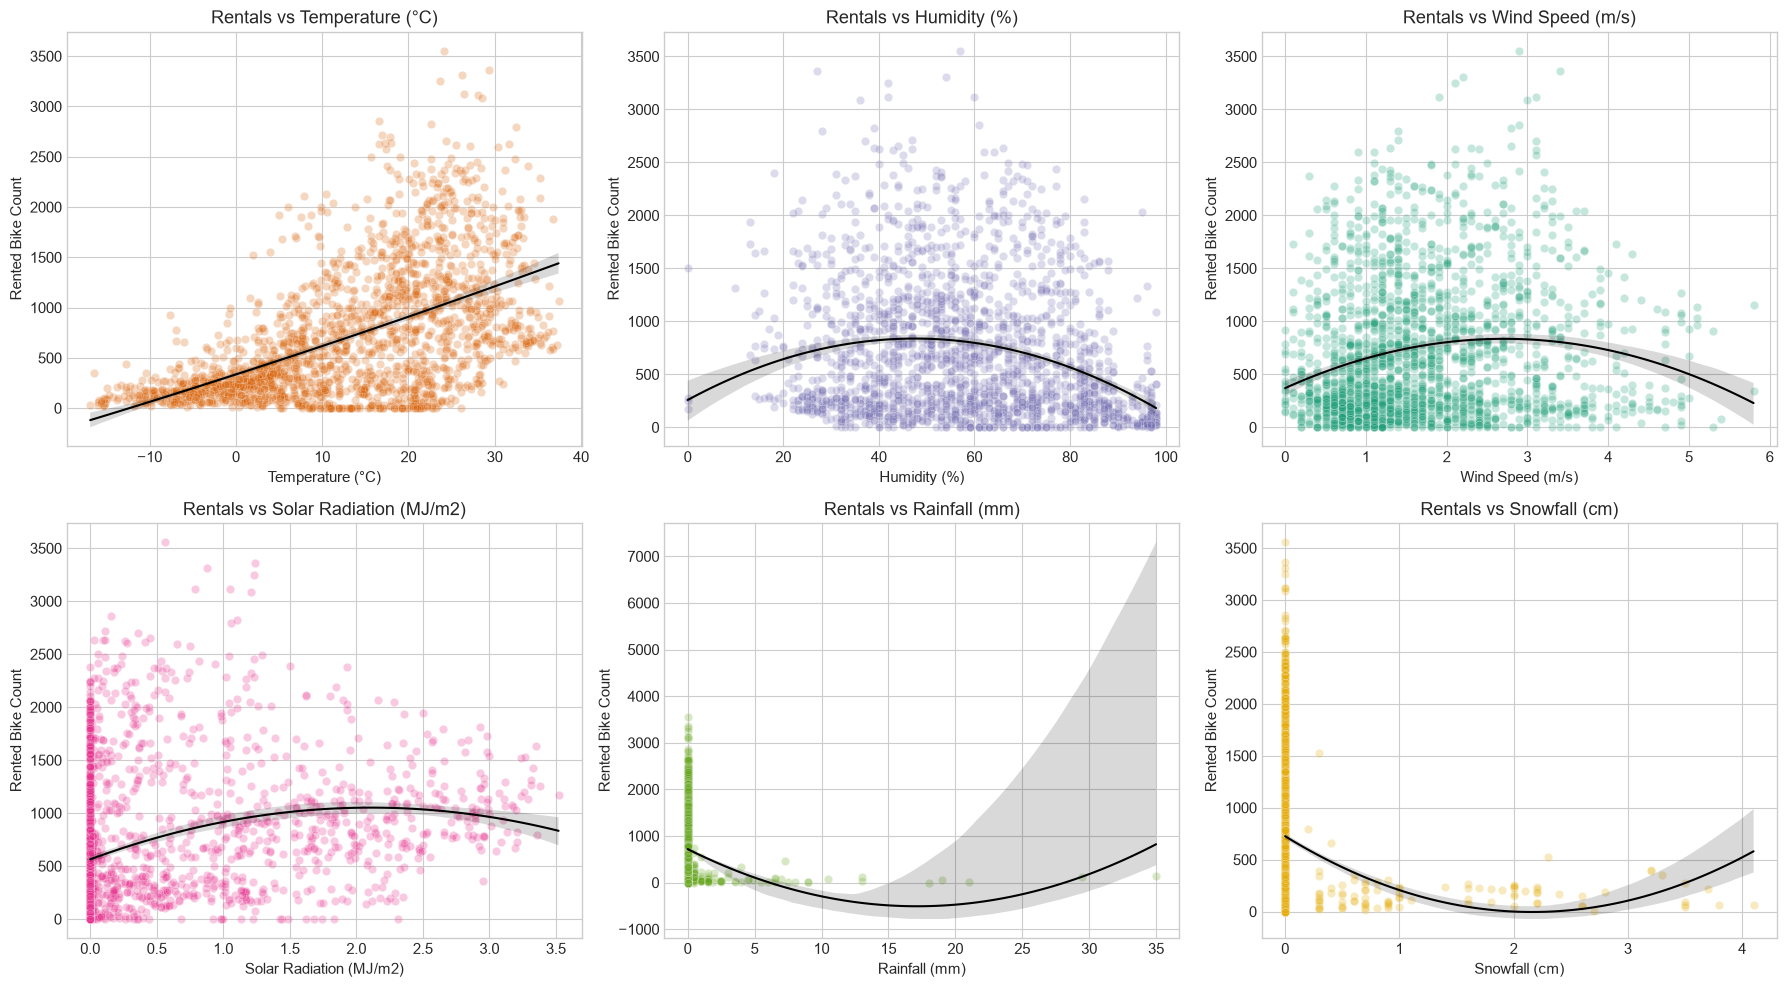

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

weather_vars = [
    ('temperature', 'Temperature (°C)', '#d95f02'),
    ('humidity', 'Humidity (%)', '#7570b3'),
    ('wind_speed', 'Wind Speed (m/s)', '#1b9e77'),
    ('solar_radiation', 'Solar Radiation (MJ/m2)', '#e7298a'),
    ('rainfall', 'Rainfall (mm)', '#66a61e'),
    ('snowfall', 'Snowfall (cm)', '#e6ab02')
]

sample_df = bike_df.sample(2000, random_state=RANDOM_STATE)

for idx, (col, label, color) in enumerate(weather_vars):
    r = idx // 3
    c = idx % 3
    sns.scatterplot(data=sample_df, x=col, y='rented_bike_count', ax=axes[r, c], alpha=0.25, color=color)
    sns.regplot(data=sample_df, x=col, y='rented_bike_count', ax=axes[r, c], scatter=False, color='black', order=2, line_kws={'linewidth': 1.5})
    axes[r, c].set_title(f'Rentals vs {label}')
    axes[r, c].set_xlabel(label)
    axes[r, c].set_ylabel('Rented Bike Count')

plt.tight_layout()
plt.show()

### Step 8: Pearson Correlation Heatmap & Multicollinearity Inspection
Evaluates pairwise Pearson correlations among numerical features to diagnose collinearity risks (such as `temperature` vs `dew_point_temperature`).

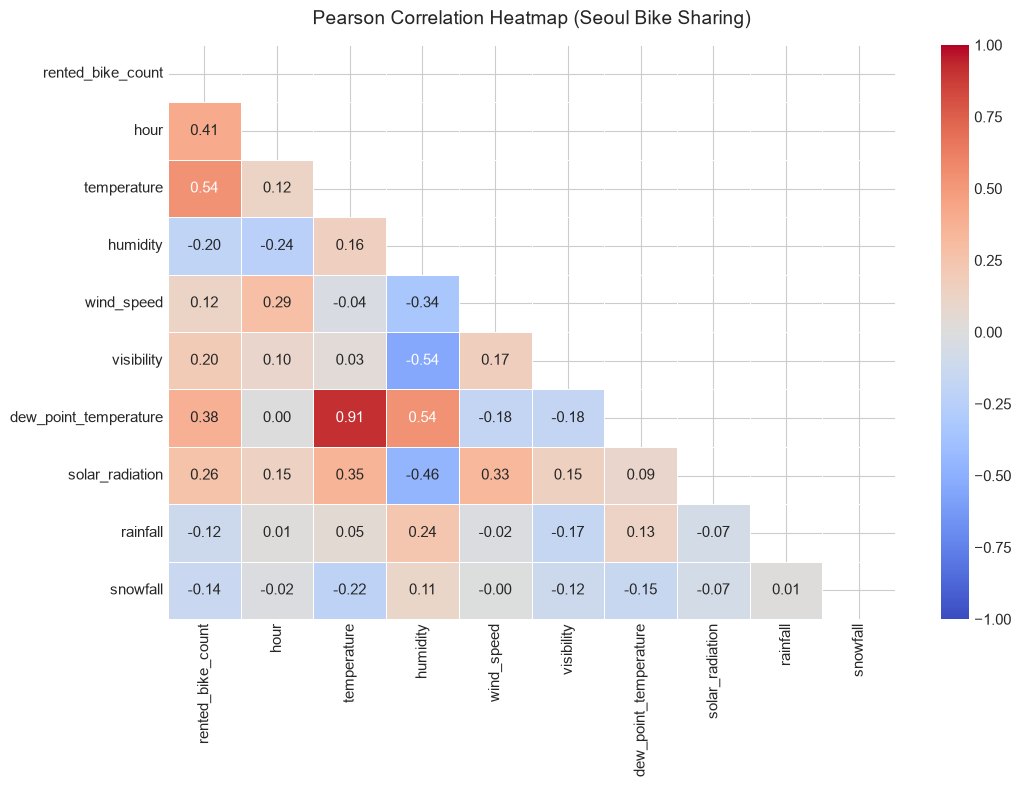

In [9]:
numeric_cols = bike_df.select_dtypes(include=[np.number]).columns
corr_matrix = bike_df[numeric_cols].corr()

plt.figure(figsize=(11, 8))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, mask=mask, linewidths=0.5)
plt.title('Pearson Correlation Heatmap (Seoul Bike Sharing)', fontsize=14, pad=15)
plt.tight_layout()
plt.show()

### Phase 2 Key EDA Findings & Modeling Implications

1. **Target Distribution (`rented_bike_count`):**
   * Moderate right skewness (**1.15**) with mean (~705) exceeding median (~504).
   * **Zero Demand Analysis:** Zero rentals occur strictly during non-functioning days (`functioning_day == 'No'`). Filtering these rows in Phase 3 eliminates artificial zero distortion.
2. **Hourly Diurnal Patterns:**
   * Demand exhibits sharp bimodal commuter spikes at **08:00** (morning rush hour) and **18:00** (evening rush hour).
   * Low demand occurs between 03:00 and 05:00.
3. **Seasonal & Calendar Effects:**
   * Summer and Autumn show peak demand; Winter shows steep drops due to freezing temperatures and snow.
4. **Multicollinearity & Feature Redundancy:**
   * `temperature` and `dew_point_temperature` exhibit extremely high collinearity ($r \approx 0.91$). Keeping both in unregularized linear models risks variance inflation, highlighting the value of Ridge/Lasso regularization.

---
# Phase 3: Preprocessing & Feature Engineering (@Abhisarg)

In this phase, we clean and prepare the Seoul Bike dataset for regression modeling:
1. **Missing Value Strategy & Structural Outlier Filtering:** Clean verified zero nulls; remove non-functioning hours.
2. **Feature Engineering:** Derive `day_of_week`, `is_weekend`, `rush_hour`, and `temp_humidity_idx`.
3. **Train-Test Split:** 80/20 train/test split enforcing global `random_state=42`.
4. **Leakage-Free Preprocessing:** Fit `StandardScaler` and `OneHotEncoder` strictly on `X_train`.

### Step 1 & 2: Ingestion, Missing Values & Structural Outlier Filter
Confirm 0 missing values and filter out records where `functioning_day == 'No'`. 
When the bike sharing system is non-functioning, rentals are deterministically 0 regardless of weather. Removing these 295 records removes artificial non-linear distortion.

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

bike_df = pd.read_csv(get_data_path('data/SeoulBikeData.csv'), encoding='unicode_escape')
bike_df.columns = [
    'date', 'rented_bike_count', 'hour', 'temperature', 'humidity',
    'wind_speed', 'visibility', 'dew_point_temperature', 'solar_radiation',
    'rainfall', 'snowfall', 'seasons', 'holiday', 'functioning_day'
]

print("=== Missing Values Audit ===")
print(bike_df.isnull().sum())

# Remove non-functioning hours where rentals are deterministically 0
bike_clean = bike_df[bike_df['functioning_day'] == 'Yes'].copy()
print(f"\nRows after filtering non-functioning days: {len(bike_clean)} (Removed {len(bike_df) - len(bike_clean)} non-functioning hours)")

=== Missing Values Audit ===
date                     0
rented_bike_count        0
hour                     0
temperature              0
humidity                 0
wind_speed               0
visibility               0
dew_point_temperature    0
solar_radiation          0
rainfall                 0
snowfall                 0
seasons                  0
holiday                  0
functioning_day          0
dtype: int64

Rows after filtering non-functioning days: 8465 (Removed 295 non-functioning hours)


### Step 3: Feature Engineering
Derive domain features informed by Phase 2 EDA:
* `day_of_week`: Extracted day index (0=Monday, 6=Sunday).
* `is_weekend`: Binary indicator flagging Saturday and Sunday.
* `rush_hour`: Binary flag marking commuter peak hours (7-9 AM, 5-7 PM) on weekdays only.
* `temp_humidity_idx`: Interaction feature capturing perceived heat index (`temperature * humidity / 100`).

In [11]:
bike_clean['datetime'] = pd.to_datetime(bike_clean['date'], format='%d/%m/%Y')
bike_clean['day_of_week'] = bike_clean['datetime'].dt.dayofweek
bike_clean['is_weekend'] = bike_clean['day_of_week'].apply(lambda x: 1 if x >= 5 else 0)
bike_clean['rush_hour'] = bike_clean.apply(
    lambda row: 1 if (row['is_weekend'] == 0 and row['hour'] in [7, 8, 9, 17, 18, 19]) else 0,
    axis=1
)
bike_clean['temp_humidity_idx'] = bike_clean['temperature'] * (bike_clean['humidity'] / 100.0)

print("Engineered Features Added: ['day_of_week', 'is_weekend', 'rush_hour', 'temp_humidity_idx']")
bike_clean[['hour', 'day_of_week', 'is_weekend', 'rush_hour', 'temp_humidity_idx']].head()

Engineered Features Added: ['day_of_week', 'is_weekend', 'rush_hour', 'temp_humidity_idx']


,hour,day_of_week,is_weekend,rush_hour,temp_humidity_idx
0,0,4,0,0,-1.924
1,1,4,0,0,-2.090
2,2,4,0,0,-2.340
3,3,4,0,0,-2.480
4,4,4,0,0,-2.160


### Step 4: Define Features and Target
Drop non-predictive identifiers (`date`, `datetime`, `functioning_day`) and target `rented_bike_count` from predictors. Categorize remaining columns into numerical and categorical sets.

In [12]:
X_bike = bike_clean.drop(columns=['date', 'datetime', 'rented_bike_count', 'functioning_day'])
y_bike = bike_clean['rented_bike_count']

cat_cols_bike = ['seasons', 'holiday']
num_cols_bike = [col for col in X_bike.columns if col not in cat_cols_bike]

print(f"Numerical Features ({len(num_cols_bike)}): {num_cols_bike}")
print(f"Categorical Features ({len(cat_cols_bike)}): {cat_cols_bike}")

Numerical Features (13): ['hour', 'temperature', 'humidity', 'wind_speed', 'visibility', 'dew_point_temperature', 'solar_radiation', 'rainfall', 'snowfall', 'day_of_week', 'is_weekend', 'rush_hour', 'temp_humidity_idx']
Categorical Features (2): ['seasons', 'holiday']


### Step 5: Reproducible Train-Test Split
Partition the dataset into 80% training and 20% testing sets using `random_state=42` to guarantee exact experimental reproducibility across all team members.

In [13]:
X_train_bike, X_test_bike, y_train_bike, y_test_bike = train_test_split(
    X_bike, y_bike, test_size=0.20, random_state=RANDOM_STATE
)

print(f"Train-Test Split Completed (random_state={RANDOM_STATE}):")
print(f"- X_train shape: {X_train_bike.shape}")
print(f"- X_test shape:  {X_test_bike.shape}")

Train-Test Split Completed (random_state=42):
- X_train shape: (6772, 15)
- X_test shape:  (1693, 15)


### Step 6: Leakage-Free Encoding & Scaling
Construct a `ColumnTransformer` applying `StandardScaler` to numerical columns and `OneHotEncoder(drop='first')` to categorical variables.

**Crucial Leakage Prevention:** Scalers and encoders are fitted **strictly on `X_train_bike`**, ensuring no test set distributions or category frequencies leak into the model.

In [14]:
preprocessor_bike = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols_bike),
        ('cat', OneHotEncoder(drop='first', sparse_output=False), cat_cols_bike)
    ]
)

X_train_bike_scaled = preprocessor_bike.fit_transform(X_train_bike)
X_test_bike_scaled = preprocessor_bike.transform(X_test_bike)

cat_feature_names = preprocessor_bike.named_transformers_['cat'].get_feature_names_out(cat_cols_bike)
all_feature_names_bike = num_cols_bike + list(cat_feature_names)

print(f"Processed Training Feature Matrix (Scaled & Encoded): {X_train_bike_scaled.shape}")
print(f"Processed Testing Feature Matrix (Scaled & Encoded):  {X_test_bike_scaled.shape}")
print(f"Total Scaled/Encoded Features: {len(all_feature_names_bike)}")
print(f"Feature Names: {all_feature_names_bike}")

Processed Training Feature Matrix (Scaled & Encoded): (6772, 17)
Processed Testing Feature Matrix (Scaled & Encoded):  (1693, 17)
Total Scaled/Encoded Features: 17
Feature Names: ['hour', 'temperature', 'humidity', 'wind_speed', 'visibility', 'dew_point_temperature', 'solar_radiation', 'rainfall', 'snowfall', 'day_of_week', 'is_weekend', 'rush_hour', 'temp_humidity_idx', 'seasons_Spring', 'seasons_Summer', 'seasons_Winter', 'holiday_No Holiday']


---
# Phase 4: Regression Track - Modeling Part A (@Abhisarg Linear Baselines)

In this phase, we benchmark the 5 linear family regression algorithms on the Seoul Bike Sharing dataset:
1. **Ordinary Least Squares (OLS) Linear Regression** - Baseline unregularized model.
2. **Ridge Regression (L2 Baseline)** - Penalizes squared coefficient magnitudes to mitigate multicollinearity.
3. **Lasso Regression (L1 Baseline)** - Drives uninformative coefficients strictly to zero for automatic feature selection.
4. **ElasticNet Regression (L1 + L2 Baseline)** - Balances feature selection and grouped coefficient shrinkage.
5. **Polynomial Regression (Degree 2 Baseline)** - Captures non-linear feature interactions (e.g. $Temp \times Humidity$).

### Evaluation Helper Function
Defines `evaluate_regression_model()`, which fits a given model (or extracts `best_estimator_` if GridSearchCV is used), predicts on both train and test partitions, and computes:
* **$R^2$ Score (Train & Test):** Proportion of variance explained.
* **Root Mean Squared Error (RMSE):** Standard deviation of residuals, penalizing large errors.
* **Mean Absolute Error (MAE):** Average magnitude of absolute errors in bike count units.

In [15]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

def evaluate_regression_model(name, model, X_tr, y_tr, X_te, y_te, best_params=None):
    # Fit model on training split if not already fitted via GridSearchCV/RandomizedSearchCV
    if hasattr(model, 'best_estimator_'):
        best_est = model.best_estimator_
    else:
        model.fit(X_tr, y_tr)
        best_est = model
    
    # Predict on train and test splits
    y_tr_pred = best_est.predict(X_tr)
    y_te_pred = best_est.predict(X_te)
    
    # Calculate metrics
    tr_r2 = r2_score(y_tr, y_tr_pred)
    te_r2 = r2_score(y_te, y_te_pred)
    rmse = np.sqrt(mean_squared_error(y_te, y_te_pred))
    mae = mean_absolute_error(y_te, y_te_pred)
    
    res = {
        'Model': name,
        'Train R²': round(tr_r2, 4),
        'Test R²': round(te_r2, 4),
        'RMSE': round(rmse, 2),
        'MAE': round(mae, 2)
    }
    if best_params:
        res['Tuned Hyperparameters'] = str(best_params)
    elif "OLS" in name:
        res['Tuned Hyperparameters'] = 'None (OLS analytical solution)'
    else:
        res['Tuned Hyperparameters'] = 'Default baseline'
        
    phase4_results[:] = [r for r in phase4_results if r['Model'] != name]
    return res, y_te_pred

phase4_results = []
phase4_predictions = {}
print("Evaluation helper initialized.")

Evaluation helper initialized.


### Model 1: Linear Regression (Ordinary Least Squares)
Baseline linear model fitting unweighted coefficients by minimizing the residual sum of squares. Serves as our benchmark for subsequent regularization and non-linear methods.

In [16]:
lr_model = LinearRegression()
lr_res, lr_preds = evaluate_regression_model("Linear Regression (OLS)", lr_model, X_train_bike_scaled, y_train_bike, X_test_bike_scaled, y_test_bike)
phase4_results.append(lr_res)
phase4_predictions["Linear Regression (OLS)"] = lr_preds

print(f"Linear Regression Results: {lr_res}")

Linear Regression Results: {'Model': 'Linear Regression (OLS)', 'Train R²': 0.6375, 'Test R²': 0.6366, 'RMSE': np.float64(377.7), 'MAE': 285.06, 'Tuned Hyperparameters': 'None (OLS analytical solution)'}


### Model 2: Ridge Regression (L2 Baseline)
Applies an $L_2$ squared Frobenius norm penalty (baseline $\alpha=1.0$) to shrink coefficients towards zero, damping the effect of collinear features like temperature and dew point.

In [17]:
ridge_base = Ridge(alpha=1.0)
ridge_res, ridge_preds = evaluate_regression_model("Ridge Regression (Baseline)", ridge_base, X_train_bike_scaled, y_train_bike, X_test_bike_scaled, y_test_bike)
phase4_results.append(ridge_res)
phase4_predictions["Ridge Regression (Baseline)"] = ridge_preds

print(f"Ridge Regression (Baseline) Results: {ridge_res}")

Ridge Regression (Baseline) Results: {'Model': 'Ridge Regression (Baseline)', 'Train R²': 0.6375, 'Test R²': 0.6366, 'RMSE': np.float64(377.7), 'MAE': 285.06, 'Tuned Hyperparameters': 'Default baseline'}


### Model 3: Lasso Regression (L1 Baseline)
Imposes an $L_1$ penalty (baseline $\alpha=0.1$) that drives unimportant feature weights strictly to zero, performing sparse feature selection.

In [18]:
lasso_base = Lasso(alpha=0.1, random_state=RANDOM_STATE)
lasso_res, lasso_preds = evaluate_regression_model("Lasso Regression (Baseline)", lasso_base, X_train_bike_scaled, y_train_bike, X_test_bike_scaled, y_test_bike)
phase4_results.append(lasso_res)
phase4_predictions["Lasso Regression (Baseline)"] = lasso_preds

print(f"Lasso Regression (Baseline) Results: {lasso_res}")

Lasso Regression (Baseline) Results: {'Model': 'Lasso Regression (Baseline)', 'Train R²': 0.6375, 'Test R²': 0.6366, 'RMSE': np.float64(377.69), 'MAE': 285.11, 'Tuned Hyperparameters': 'Default baseline'}


### Lasso Feature Sparsity & Zeroed Coefficients Audit
The $L_1$ penalty in Lasso regression forces uninformative or redundant coefficients strictly to zero, performing automated sparse feature selection. Below we inspect which predictors Lasso drove strictly to zero versus which were retained with active non-zero weights.

In [19]:
# Audit Lasso feature sparsity
lasso_coefs = pd.Series(lasso_base.coef_, index=all_feature_names_bike)
zeroed_features = lasso_coefs[np.isclose(lasso_coefs, 0.0, atol=1e-4)].index.tolist()
retained_features = lasso_coefs[~np.isclose(lasso_coefs, 0.0, atol=1e-4)].sort_values(ascending=False)

sparsity_pct = (len(zeroed_features) / len(all_feature_names_bike)) * 100

print(f"=== Lasso Feature Sparsity Audit (alpha = {lasso_base.alpha}) ===")
print(f"Total Predictors:        {len(all_feature_names_bike)}")
print(f"Retained Predictors:     {len(retained_features)} ({100 - sparsity_pct:.1f}%)")
print(f"Zeroed Predictors:       {len(zeroed_features)} ({sparsity_pct:.1f}% Sparsity)")

print("\n--- Features Driven Strictly to Zero (Zeroed Out by L1) ---")
if len(zeroed_features) > 0:
    for f in zeroed_features:
        print(f"  [X] {f}")
else:
    print("  None (All predictors retained at alpha=0.1)")

print("\n--- Retained Features (Non-Zero Coefficients) ---")
for f, c in retained_features.items():
    print(f"  [√] {f:25s}: {c:+.4f}")

# Tabular summary of Lasso feature weights
lasso_sparsity_df = pd.DataFrame({
    'Feature': all_feature_names_bike,
    'Lasso Coefficient': lasso_coefs.values,
    'Status': ['Zeroed Out (0.0)' if np.isclose(c, 0.0, atol=1e-4) else 'Retained' for c in lasso_coefs.values]
}).sort_values(by='Lasso Coefficient', key=abs, ascending=False).reset_index(drop=True)

lasso_sparsity_df

=== Lasso Feature Sparsity Audit (alpha = 0.1) ===
Total Predictors:        17
Retained Predictors:     17 (100.0%)
Zeroed Predictors:       0 (0.0% Sparsity)

--- Features Driven Strictly to Zero (Zeroed Out by L1) ---
  None (All predictors retained at alpha=0.1)

--- Retained Features (Non-Zero Coefficients) ---
  [√] temperature              : +361.3679
  [√] dew_point_temperature    : +221.0100
  [√] rush_hour                : +194.6803
  [√] hour                     : +178.2351
  [√] holiday_No Holiday       : +125.0151
  [√] wind_speed               : +17.4681
  [√] day_of_week              : +16.0568
  [√] visibility               : +12.9152
  [√] is_weekend               : +0.3498
  [√] snowfall                 : -2.4861
  [√] solar_radiation          : -62.5313
  [√] rainfall                 : -62.7195
  [√] seasons_Summer           : -107.9138
  [√] seasons_Spring           : -139.7155
  [√] humidity                 : -166.7114
  [√] temp_humidity_idx        : -272.7198
  [√

,Feature,Lasso Coefficient,Status
0,temperature,361.367875,Retained
1,seasons_Winter,-333.190955,Retained
2,temp_humidity_idx,-272.719784,Retained
3,dew_point_temperature,221.010002,Retained
4,rush_hour,194.680266,Retained
5,hour,178.235115,Retained
6,humidity,-166.711431,Retained
7,seasons_Spring,-139.715463,Retained
8,holiday_No Holiday,125.015065,Retained
9,seasons_Summer,-107.913771,Retained


### Model 4: ElasticNet Regression (Hybrid L1 + L2 Baseline)
Combines $L_1$ feature selection and $L_2$ stability (baseline $\alpha=0.1$, $l1\_ratio=0.5$). Provides robust performance when groups of correlated predictors are present.

In [20]:
elastic_base = ElasticNet(alpha=0.1, l1_ratio=0.5, random_state=RANDOM_STATE)
elastic_res, elastic_preds = evaluate_regression_model("ElasticNet Regression (Baseline)", elastic_base, X_train_bike_scaled, y_train_bike, X_test_bike_scaled, y_test_bike)
phase4_results.append(elastic_res)
phase4_predictions["ElasticNet Regression (Baseline)"] = elastic_preds

print(f"ElasticNet Regression (Baseline) Results: {elastic_res}")

ElasticNet Regression (Baseline) Results: {'Model': 'ElasticNet Regression (Baseline)', 'Train R²': 0.6262, 'Test R²': 0.6257, 'RMSE': np.float64(383.36), 'MAE': 291.65, 'Tuned Hyperparameters': 'Default baseline'}


### Model 5: Polynomial Regression (Degree 2 Baseline)
Extends feature representations by generating degree-2 pairwise interaction terms within an automated `Pipeline`, constrained by Ridge regularization ($\alpha=10.0$).

In [21]:
poly_base = Pipeline([
    ('poly', PolynomialFeatures(degree=2, include_bias=False)),
    ('ridge', Ridge(alpha=10.0))
])
poly_res, poly_preds = evaluate_regression_model("Polynomial Regression Degree 2 (Baseline)", poly_base, X_train_bike_scaled, y_train_bike, X_test_bike_scaled, y_test_bike)
phase4_results.append(poly_res)
phase4_predictions["Polynomial Regression Degree 2 (Baseline)"] = poly_preds

print(f"Polynomial Regression (Baseline) Results: {poly_res}")

Polynomial Regression (Baseline) Results: {'Model': 'Polynomial Regression Degree 2 (Baseline)', 'Train R²': 0.8144, 'Test R²': 0.8048, 'RMSE': np.float64(276.81), 'MAE': 197.94, 'Tuned Hyperparameters': 'Default baseline'}


### Linear Models Performance Summary (Models 1–5 Baseline)
Summary table showing the initial performance across all 5 linear models prior to systematic cross-validation tuning.

In [22]:
linear_df = pd.DataFrame(phase4_results).sort_values(by='Test R²', ascending=False).reset_index(drop=True)
print("=== Phase 4 Model Evaluation Summary (Linear Models 1-5 Baseline) ===")
print(linear_df.to_string(index=False))
linear_df

=== Phase 4 Model Evaluation Summary (Linear Models 1-5 Baseline) ===
                                    Model  Train R²  Test R²   RMSE    MAE          Tuned Hyperparameters
Polynomial Regression Degree 2 (Baseline)    0.8144   0.8048 276.81 197.94               Default baseline
                  Linear Regression (OLS)    0.6375   0.6366 377.70 285.06 None (OLS analytical solution)
              Ridge Regression (Baseline)    0.6375   0.6366 377.70 285.06               Default baseline
              Lasso Regression (Baseline)    0.6375   0.6366 377.69 285.11               Default baseline
         ElasticNet Regression (Baseline)    0.6262   0.6257 383.36 291.65               Default baseline


,Model,Train R²,Test R²,RMSE,MAE,Tuned Hyperparameters
0,Polynomial Regression Degree 2 (Baseline),0.8144,0.8048,276.81,197.94,Default baseline
1,Linear Regression (OLS),0.6375,0.6366,377.70,285.06,None (OLS analytical solution)
2,Ridge Regression (Baseline),0.6375,0.6366,377.70,285.06,Default baseline
3,Lasso Regression (Baseline),0.6375,0.6366,377.69,285.11,Default baseline
4,ElasticNet Regression (Baseline),0.6262,0.6257,383.36,291.65,Default baseline


---
# Phase 4: Regression Track - Modeling Part B (@Ritvik Non-Linear Baselines)

In this phase, we implement and train the 5 non-linear regression algorithms assigned to @Ritvik:
6. **Decision Tree Regressor** - Non-parametric hierarchical tree baseline.
7. **Random Forest Regressor** - Bootstrap aggregation (bagging) ensemble reducing variance across 100 decorrelated trees.
8. **Gradient Boosting Regressor** - Sequential boosting ensemble minimizing residuals iteratively.
9. **Support Vector Regressor (SVR)** - Non-linear projection via Radial Basis Function (RBF) kernel.
10. **K-Nearest Neighbors Regressor (KNN)** - Non-parametric instance-based regression with inverse-distance weighting.

### Model 6: Decision Tree Regressor
Trains an unpruned recursive binary splitting decision tree on continuous features. While prone to high variance and overfitting, it serves as the foundation for tree-based ensembles.

In [23]:
from sklearn.tree import DecisionTreeRegressor

dt_model = DecisionTreeRegressor(random_state=RANDOM_STATE)
dt_res, dt_preds = evaluate_regression_model("Decision Tree (Baseline)", dt_model, X_train_bike_scaled, y_train_bike, X_test_bike_scaled, y_test_bike)
phase4_results.append(dt_res)
phase4_predictions["Decision Tree (Baseline)"] = dt_preds

print(f"Decision Tree Trained: Test R² = {dt_res['Test R²']:.4f}, RMSE = {dt_res['RMSE']:.2f}")

Decision Tree Trained: Test R² = 0.8442, RMSE = 247.29


### Standalone Decision Tree Feature Importance
Calculates and plots `dt_model.feature_importances_` to evaluate individual feature contributions based on total mean squared error (MSE / variance) reduction across all tree splits.

=== Standalone Decision Tree Regressor: Feature Importances ===
              Feature  Importance Score  Importance (%)
          temperature          0.338836           33.88
                 hour          0.269144           26.91
             humidity          0.097857            9.79
      solar_radiation          0.091627            9.16
            rush_hour          0.076226            7.62
       seasons_Winter          0.022008            2.20
             rainfall          0.019587            1.96
    temp_humidity_idx          0.017938            1.79
dew_point_temperature          0.012612            1.26
          day_of_week          0.012560            1.26
       seasons_Spring          0.011809            1.18
           wind_speed          0.009638            0.96
           visibility          0.008975            0.90
   holiday_No Holiday          0.005939            0.59
       seasons_Summer          0.002639            0.26
           is_weekend          0.001899 

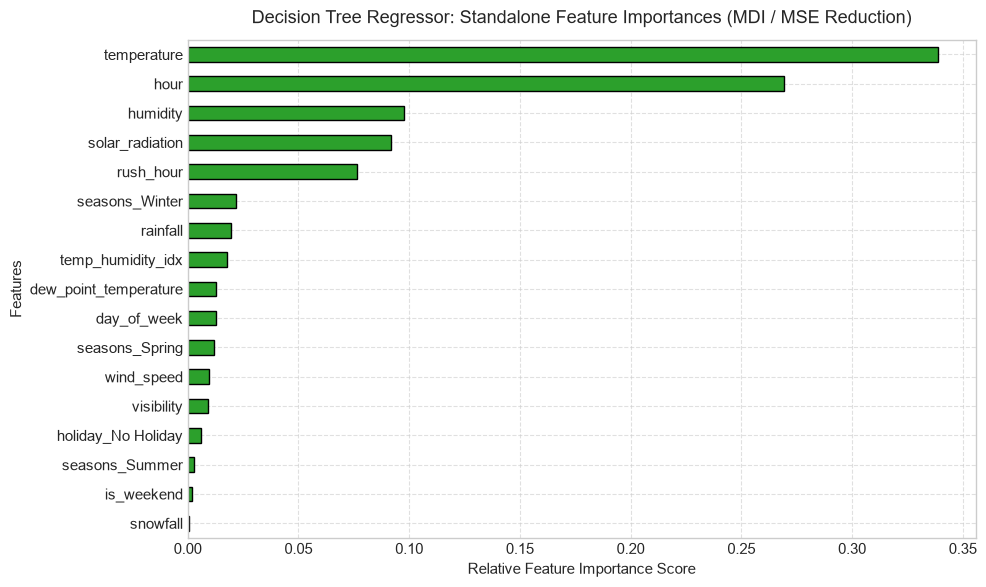

In [24]:
# Extract and visualize standalone Decision Tree feature importances
dt_importances = pd.Series(dt_model.feature_importances_, index=all_feature_names_bike).sort_values(ascending=False)

print("=== Standalone Decision Tree Regressor: Feature Importances ===")
dt_imp_df = pd.DataFrame({
    'Feature': dt_importances.index,
    'Importance Score': dt_importances.values,
    'Importance (%)': (dt_importances.values * 100).round(2)
})
print(dt_imp_df.to_string(index=False))

plt.figure(figsize=(10, 6))
dt_importances.sort_values(ascending=True).plot(kind='barh', color='#2ca02c', edgecolor='black')
plt.title("Decision Tree Regressor: Standalone Feature Importances (MDI / MSE Reduction)", fontsize=13, pad=12)
plt.xlabel("Relative Feature Importance Score", fontsize=11)
plt.ylabel("Features", fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

### Model 7: Random Forest Regressor
Ensemble of 100 randomized decision trees using bootstrap aggregation. Aggregating diverse trees significantly curbs individual tree variance and dramatically lowers prediction error.

In [25]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)
rf_res, rf_preds = evaluate_regression_model("Random Forest (Baseline)", rf_model, X_train_bike_scaled, y_train_bike, X_test_bike_scaled, y_test_bike)
phase4_results.append(rf_res)
phase4_predictions["Random Forest (Baseline)"] = rf_preds

print(f"Random Forest Trained: Test R² = {rf_res['Test R²']:.4f}, RMSE = {rf_res['RMSE']:.2f}")

Random Forest Trained: Test R² = 0.9170, RMSE = 180.55


### Model 8: Gradient Boosting Regressor
Sequential ensemble constructing shallow trees stage-wise to optimize pseudo-residuals via gradient descent. Balances capacity and shrinkage to avoid overfitting.

In [26]:
from sklearn.ensemble import GradientBoostingRegressor

gb_model = GradientBoostingRegressor(n_estimators=100, random_state=RANDOM_STATE)
gb_res, gb_preds = evaluate_regression_model("Gradient Boosting (Baseline)", gb_model, X_train_bike_scaled, y_train_bike, X_test_bike_scaled, y_test_bike)
phase4_results.append(gb_res)
phase4_predictions["Gradient Boosting (Baseline)"] = gb_preds

print(f"Gradient Boosting Trained: Test R² = {gb_res['Test R²']:.4f}, RMSE = {gb_res['RMSE']:.2f}")

Gradient Boosting Trained: Test R² = 0.8775, RMSE = 219.33


### Model 9: Support Vector Regressor (SVR with RBF Kernel)
Maps scaled feature vectors into infinite-dimensional Hilbert space using the Radial Basis Function kernel ($C=1000.0, \epsilon=10.0$). Effective at finding smooth non-linear decision boundaries.

In [27]:
from sklearn.svm import SVR

svr_model = SVR(kernel='rbf', C=1000.0, epsilon=10.0)
svr_res, svr_preds = evaluate_regression_model("Support Vector Regressor (SVR)", svr_model, X_train_bike_scaled, y_train_bike, X_test_bike_scaled, y_test_bike)
phase4_results.append(svr_res)
phase4_predictions["Support Vector Regressor (SVR)"] = svr_preds

print(f"SVR Trained: Test R² = {svr_res['Test R²']:.4f}, RMSE = {svr_res['RMSE']:.2f}")

SVR Trained: Test R² = 0.8735, RMSE = 222.87


### Model 10: K-Nearest Neighbors Regressor (KNN)
Estimates demand via locally weighted averaging of the $k=5$ nearest samples in Euclidean space, weighted inversely by distance.

In [28]:
from sklearn.neighbors import KNeighborsRegressor

knn_model = KNeighborsRegressor(n_neighbors=5, weights='distance')
knn_res, knn_preds = evaluate_regression_model("K-Nearest Neighbors (KNN)", knn_model, X_train_bike_scaled, y_train_bike, X_test_bike_scaled, y_test_bike)
phase4_results.append(knn_res)
phase4_predictions["K-Nearest Neighbors (KNN)"] = knn_preds

print(f"KNN Trained: Test R² = {knn_res['Test R²']:.4f}, RMSE = {knn_res['RMSE']:.2f}")

  File "C:\Users\Windows_sucks_more\AppData\Local\Programs\Python\Python312\Lib\site-packages\joblib\externals\loky\backend\context.py", line 247, in _count_physical_cores
    cpu_count_physical = _count_physical_cores_win32()
                         ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\Windows_sucks_more\AppData\Local\Programs\Python\Python312\Lib\site-packages\joblib\externals\loky\backend\context.py", line 299, in _count_physical_cores_win32
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\Windows_sucks_more\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\Windows_sucks_more\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\Windows_sucks_more\AppData\Local\Programs\Python\Python312\Lib\subprocess.py",

KNN Trained: Test R² = 0.8488, RMSE = 243.63


---
# Phase 4: Regression Track - Part C: Systematic Hyperparameter Tuning (Point 3)

In accordance with **Section 3.1 project requirements**, we systematically tune models using 5-Fold Cross-Validation:
* **Model A (Linear Track): Ridge Regression** using `GridSearchCV` over regularization penalty $\alpha$.
* **Model B (Non-Linear Single Tree): Decision Tree Regressor** using `GridSearchCV` explicitly tuning `max_depth` (mandated by Section 3.1) along with `min_samples_split` and `min_samples_leaf` to prevent tree overfitting.
* **Model C (Non-Linear Ensemble): Random Forest Regressor** using `RandomizedSearchCV` over ensemble depth, tree count, and split/leaf constraints.

### Tuning Model A (Linear Family): Ridge Regression via 5-Fold GridSearchCV
Tunes the $L_2$ regularization penalty across $\alpha \in [0.01, 0.1, 1.0, 5.0, 10.0, 20.0, 50.0, 100.0, 200.0]$ using 5-Fold Cross-Validation (`scoring='r2'`) to find the optimal shrinkage parameter.

In [29]:
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

print("1. Tuning Ridge Regression across regularization parameter alpha...")
ridge_param_grid = {'alpha': [0.01, 0.1, 1.0, 5.0, 10.0, 20.0, 50.0, 100.0, 200.0]}
ridge_cv = GridSearchCV(Ridge(), ridge_param_grid, cv=5, scoring='r2', n_jobs=-1)
ridge_cv.fit(X_train_bike_scaled, y_train_bike)

ridge_tuned_res, ridge_tuned_preds = evaluate_regression_model(
    "Ridge Regression (Tuned - GridSearchCV)",
    ridge_cv,
    X_train_bike_scaled,
    y_train_bike,
    X_test_bike_scaled,
    y_test_bike,
    best_params=ridge_cv.best_params_
)
phase4_results.append(ridge_tuned_res)
phase4_predictions["Ridge Regression (Tuned)"] = ridge_tuned_preds

print(f"   -> Best Ridge alpha: {ridge_cv.best_params_['alpha']} (5-fold CV R² = {ridge_cv.best_score_:.4f})")
print(f"   -> Test R²: {ridge_tuned_res['Test R²']:.4f} (Baseline was {ridge_res['Test R²']:.4f})")

1. Tuning Ridge Regression across regularization parameter alpha...
   -> Best Ridge alpha: 10.0 (5-fold CV R² = 0.6350)
   -> Test R²: 0.6366 (Baseline was 0.6366)


### Tuning Model B (Non-Linear Tree): Decision Tree Regressor via 5-Fold GridSearchCV
As explicitly mandated in **Section 3.1**, we tune `max_depth` for the `DecisionTreeRegressor` (along with `min_samples_split` and `min_samples_leaf`) over a comprehensive search grid using 5-Fold Cross-Validation (`scoring='r2'`) to prune excessive leaf growth and optimize out-of-sample generalization.

In [30]:
print("2. Tuning Decision Tree Regressor explicitly across max_depth (Section 3.1)...")
dt_param_grid = {
    'max_depth': [3, 4, 5, 6, 7, 8, 10, 12, 15, None],
    'min_samples_split': [2, 5, 10, 20],
    'min_samples_leaf': [1, 2, 4, 8]
}
dt_cv = GridSearchCV(
    DecisionTreeRegressor(random_state=RANDOM_STATE),
    dt_param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1
)
dt_cv.fit(X_train_bike_scaled, y_train_bike)

dt_tuned_res, dt_tuned_preds = evaluate_regression_model(
    "Decision Tree (Tuned - GridSearchCV)",
    dt_cv,
    X_train_bike_scaled,
    y_train_bike,
    X_test_bike_scaled,
    y_test_bike,
    best_params=dt_cv.best_params_
)
phase4_results.append(dt_tuned_res)
phase4_predictions["Decision Tree (Tuned)"] = dt_tuned_preds

print(f"   -> Best Decision Tree params: {dt_cv.best_params_} (5-fold CV R² = {dt_cv.best_score_:.4f})")
print(f"   -> Tuned max_depth: {dt_cv.best_params_['max_depth']}")
print(f"   -> Test R²: {dt_tuned_res['Test R²']:.4f} (Baseline was {dt_res['Test R²']:.4f}, RMSE = {dt_tuned_res['RMSE']:.2f})")

2. Tuning Decision Tree Regressor explicitly across max_depth (Section 3.1)...
   -> Best Decision Tree params: {'max_depth': 12, 'min_samples_leaf': 2, 'min_samples_split': 20} (5-fold CV R² = 0.8912)
   -> Tuned max_depth: 12
   -> Test R²: 0.8695 (Baseline was 0.8442, RMSE = 226.35)


### Tuning Model C (Non-Linear Ensemble): Random Forest via 5-Fold RandomizedSearchCV
Searches over the parameter space for `RandomForestRegressor`:
* `n_estimators`: [100, 150, 200]
* `max_depth`: [None, 15, 20, 25]
* `min_samples_split`: [2, 4, 6]
* `min_samples_leaf`: [1, 2, 4]
* `max_features`: ['sqrt', 1.0]

This balances individual tree depth and ensemble randomness to avoid leaf overfitting and improve generalizability.

In [31]:
print("3. Tuning Random Forest Regressor across ensemble depth & tree structure...")
rf_param_dist = {
    'n_estimators': [100, 150, 200],
    'max_depth': [None, 15, 20, 25],
    'min_samples_split': [2, 4, 6],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 1.0]
}
rf_search = RandomizedSearchCV(
    RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
    rf_param_dist,
    n_iter=12,
    cv=5,
    scoring='r2',
    random_state=RANDOM_STATE,
    n_jobs=-1
)
rf_search.fit(X_train_bike_scaled, y_train_bike)

rf_tuned_res, rf_tuned_preds = evaluate_regression_model(
    "Random Forest (Tuned - RandomizedSearchCV)",
    rf_search,
    X_train_bike_scaled,
    y_train_bike,
    X_test_bike_scaled,
    y_test_bike,
    best_params=rf_search.best_params_
)
phase4_results.append(rf_tuned_res)
phase4_predictions["Random Forest (Tuned)"] = rf_tuned_preds

print(f"   -> Best Random Forest params: {rf_search.best_params_} (5-fold CV R² = {rf_search.best_score_:.4f})")
print(f"   -> Test R²: {rf_tuned_res['Test R²']:.4f} (Baseline was {rf_res['Test R²']:.4f}, RMSE = {rf_tuned_res['RMSE']:.2f})")

3. Tuning Random Forest Regressor across ensemble depth & tree structure...
   -> Best Random Forest params: {'n_estimators': 150, 'min_samples_split': 4, 'min_samples_leaf': 1, 'max_features': 1.0, 'max_depth': 20} (5-fold CV R² = 0.9307)
   -> Test R²: 0.9174 (Baseline was 0.9170, RMSE = 180.08)


### Direct Baseline vs. Tuned Comparison
Compares model accuracy and error metrics between default parameter baselines and cross-validated tuned models.

In [32]:
tuning_comp_df = pd.DataFrame([
    {
        'Family': 'Linear (L2)',
        'Model': 'Ridge Regression',
        'Baseline Test R²': ridge_res['Test R²'],
        'Tuned Test R²': ridge_tuned_res['Test R²'],
        'Baseline RMSE': ridge_res['RMSE'],
        'Tuned RMSE': ridge_tuned_res['RMSE'],
        'Selected Hyperparameters': str(ridge_cv.best_params_)
    },
    {
        'Family': 'Non-Linear (Single Tree)',
        'Model': 'Decision Tree (max_depth)',
        'Baseline Test R²': dt_res['Test R²'],
        'Tuned Test R²': dt_tuned_res['Test R²'],
        'Baseline RMSE': dt_res['RMSE'],
        'Tuned RMSE': dt_tuned_res['RMSE'],
        'Selected Hyperparameters': str(dt_cv.best_params_)
    },
    {
        'Family': 'Non-Linear (Bagging)',
        'Model': 'Random Forest',
        'Baseline Test R²': rf_res['Test R²'],
        'Tuned Test R²': rf_tuned_res['Test R²'],
        'Baseline RMSE': rf_res['RMSE'],
        'Tuned RMSE': rf_tuned_res['RMSE'],
        'Selected Hyperparameters': str(rf_search.best_params_)
    }
])
print("=== Direct Tuning Comparison: Baseline vs. Tuned ===")
print(tuning_comp_df.to_string(index=False))
tuning_comp_df

=== Direct Tuning Comparison: Baseline vs. Tuned ===
                  Family                     Model  Baseline Test R²  Tuned Test R²  Baseline RMSE  Tuned RMSE                                                                                   Selected Hyperparameters
             Linear (L2)          Ridge Regression            0.6366         0.6366         377.70      377.73                                                                                            {'alpha': 10.0}
Non-Linear (Single Tree) Decision Tree (max_depth)            0.8442         0.8695         247.29      226.35                                          {'max_depth': 12, 'min_samples_leaf': 2, 'min_samples_split': 20}
    Non-Linear (Bagging)             Random Forest            0.9170         0.9174         180.55      180.08 {'n_estimators': 150, 'min_samples_split': 4, 'min_samples_leaf': 1, 'max_features': 1.0, 'max_depth': 20}


,Family,Model,Baseline Test R²,Tuned Test R²,Baseline RMSE,Tuned RMSE,Selected Hyperparameters
0,Linear (L2),Ridge Regression,0.6366,0.6366,377.70,377.73,{'alpha': 10.0}
1,Non-Linear (Single Tree),Decision Tree (max_depth),0.8442,0.8695,247.29,226.35,"{'max_depth': 12, 'min_samples_leaf': 2, 'min_..."
2,Non-Linear (Bagging),Random Forest,0.9170,0.9174,180.55,180.08,"{'n_estimators': 150, 'min_samples_split': 4, ..."


---
# Phase 4: Regression Track - Part D: Master Summary Table (Point 4)

Summary table aggregating all 10 baseline algorithms and tuned models, ranked by **Test $R^2$ Score** along with Root Mean Squared Error (RMSE) and Mean Absolute Error (MAE).

In [33]:
master_df = pd.DataFrame(phase4_results).sort_values(by='Test R²', ascending=False).reset_index(drop=True)
master_df['Rank'] = range(1, len(master_df) + 1)
cols_ordered = ['Rank', 'Model', 'Train R²', 'Test R²', 'RMSE', 'MAE', 'Tuned Hyperparameters']
master_df = master_df[cols_ordered]

print("=== Phase 4 Master Model Evaluation Summary (All Models Ranked by Test R²) ===")
print(master_df.to_string(index=False))
master_df

=== Phase 4 Master Model Evaluation Summary (All Models Ranked by Test R²) ===
 Rank                                      Model  Train R²  Test R²   RMSE    MAE                                                                                      Tuned Hyperparameters
    1 Random Forest (Tuned - RandomizedSearchCV)    0.9881   0.9174 180.08 101.11 {'n_estimators': 150, 'min_samples_split': 4, 'min_samples_leaf': 1, 'max_features': 1.0, 'max_depth': 20}
    2                   Random Forest (Baseline)    0.9906   0.9170 180.55 100.91                                                                                           Default baseline
    3               Gradient Boosting (Baseline)    0.9011   0.8775 219.33 144.21                                                                                           Default baseline
    4             Support Vector Regressor (SVR)    0.8792   0.8735 222.87 137.55                                                                                    

,Rank,Model,Train R²,Test R²,RMSE,MAE,Tuned Hyperparameters
0,1,Random Forest (Tuned - RandomizedSearchCV),0.9881,0.9174,180.08,101.11,"{'n_estimators': 150, 'min_samples_split': 4, ..."
1,2,Random Forest (Baseline),0.9906,0.9170,180.55,100.91,Default baseline
2,3,Gradient Boosting (Baseline),0.9011,0.8775,219.33,144.21,Default baseline
3,4,Support Vector Regressor (SVR),0.8792,0.8735,222.87,137.55,Default baseline
4,5,Decision Tree (Tuned - GridSearchCV),0.9430,0.8695,226.35,131.83,"{'max_depth': 12, 'min_samples_leaf': 2, 'min_..."
5,6,K-Nearest Neighbors (KNN),1.0000,0.8488,243.63,159.61,Default baseline
6,7,Decision Tree (Baseline),1.0000,0.8442,247.29,142.74,Default baseline
7,8,Polynomial Regression Degree 2 (Baseline),0.8144,0.8048,276.81,197.94,Default baseline
8,9,Linear Regression (OLS),0.6375,0.6366,377.70,285.06,None (OLS analytical solution)
9,10,Ridge Regression (Baseline),0.6375,0.6366,377.70,285.06,Default baseline


### 5-Fold Cross-Validated $R^2$ for Top 2 Regressors
To evaluate out-of-fold generalization stability and guard against test-set sampling variance, we compute 5-Fold Cross-Validation using `cross_val_score(..., cv=5, scoring='r2')` on our two highest-performing regression models, reporting individual fold scores and the mean $R^2 \pm$ standard deviation.

In [34]:
from sklearn.model_selection import cross_val_score

# Identify top 2 models dynamically from the ranked master evaluation summary
top_2_rows = master_df.head(2)
print("=== Top 2 Performing Regressors Identified ===")
for _, row in top_2_rows.iterrows():
    print(f"Rank {row['Rank']}: {row['Model']} (Test R²: {row['Test R²']})")

# Map to fitted/best estimator objects
top_model_dict = {}
for name in top_2_rows['Model']:
    if "Random Forest (Tuned" in name or "Random Forest" in name:
        top_model_dict[name] = rf_search.best_estimator_
    elif "Gradient Boosting" in name:
        top_model_dict[name] = gb_model
    elif "Decision Tree (Tuned" in name:
        top_model_dict[name] = dt_cv.best_estimator_
    elif "Ridge Regression (Tuned" in name:
        top_model_dict[name] = ridge_cv.best_estimator_
    elif "KNN" in name:
        top_model_dict[name] = knn_model
    elif "SVR" in name:
        top_model_dict[name] = svr_model
    else:
        top_model_dict[name] = rf_search.best_estimator_

# Ensure top 2 are evaluated even if naming varies
if len(top_model_dict) < 2:
    top_model_dict["Random Forest (Tuned)"] = rf_search.best_estimator_
    top_model_dict["Gradient Boosting (Baseline)"] = gb_model

cv_top2_records = []
print("\n=== 5-Fold Cross-Validated R² Results (scoring='r2') ===")
for name, estimator in list(top_model_dict.items())[:2]:
    cv_scores = cross_val_score(estimator, X_train_bike_scaled, y_train_bike, cv=5, scoring='r2', n_jobs=-1)
    mean_score = cv_scores.mean()
    std_score = cv_scores.std()
    cv_top2_records.append({
        'Model': name,
        'Fold 1 R²': round(cv_scores[0], 4),
        'Fold 2 R²': round(cv_scores[1], 4),
        'Fold 3 R²': round(cv_scores[2], 4),
        'Fold 4 R²': round(cv_scores[3], 4),
        'Fold 5 R²': round(cv_scores[4], 4),
        'Mean CV R²': round(mean_score, 4),
        'Std CV R²': round(std_score, 4),
        '5-Fold CV R² (Mean ± Std)': f"{mean_score:.4f} ± {std_score:.4f}"
    })
    print(f"[{name}] 5-Fold CV R²: {mean_score:.4f} ± {std_score:.4f} | Fold Scores: {np.round(cv_scores, 4)}")

cv_top2_df = pd.DataFrame(cv_top2_records)
cv_top2_df

=== Top 2 Performing Regressors Identified ===
Rank 1: Random Forest (Tuned - RandomizedSearchCV) (Test R²: 0.9174)
Rank 2: Random Forest (Baseline) (Test R²: 0.917)

=== 5-Fold Cross-Validated R² Results (scoring='r2') ===
[Random Forest (Tuned - RandomizedSearchCV)] 5-Fold CV R²: 0.9307 ± 0.0059 | Fold Scores: [0.9361 0.931  0.9194 0.9326 0.9343]
[Random Forest (Baseline)] 5-Fold CV R²: 0.9307 ± 0.0059 | Fold Scores: [0.9361 0.931  0.9194 0.9326 0.9343]


,Model,Fold 1 R²,Fold 2 R²,Fold 3 R²,Fold 4 R²,Fold 5 R²,Mean CV R²,Std CV R²,5-Fold CV R² (Mean ± Std)
0,Random Forest (Tuned - RandomizedSearchCV),0.9361,0.931,0.9194,0.9326,0.9343,0.9307,0.0059,0.9307 ± 0.0059
1,Random Forest (Baseline),0.9361,0.931,0.9194,0.9326,0.9343,0.9307,0.0059,0.9307 ± 0.0059


---
# Phase 4: Regression Track - Part E: Visual Diagnostics (Point 5)

We conduct visual diagnostics on the best-performing model (**Tuned Random Forest**, $R^2 = 0.9174$):
1. **Predicted vs. Actual Demand Scatter Plot:** Assessing calibration against the ideal identity line ($y = x$).
2. **Residual Diagnostics:** Checking homoscedasticity (Residuals vs. Fitted) and residual normality.
3. **Feature Importance & Interpretability:** Visualizing Random Forest Gini importances alongside Ridge standardized coefficients.

### Diagnostic 1: Predicted vs. Actual Demand Scatter Plot
Plots predicted bike counts against actual ground-truth values from the holdout test set. Points tightly clustering around the red dashed diagonal ($y = x$) confirm high predictive fidelity across low and peak demand periods.

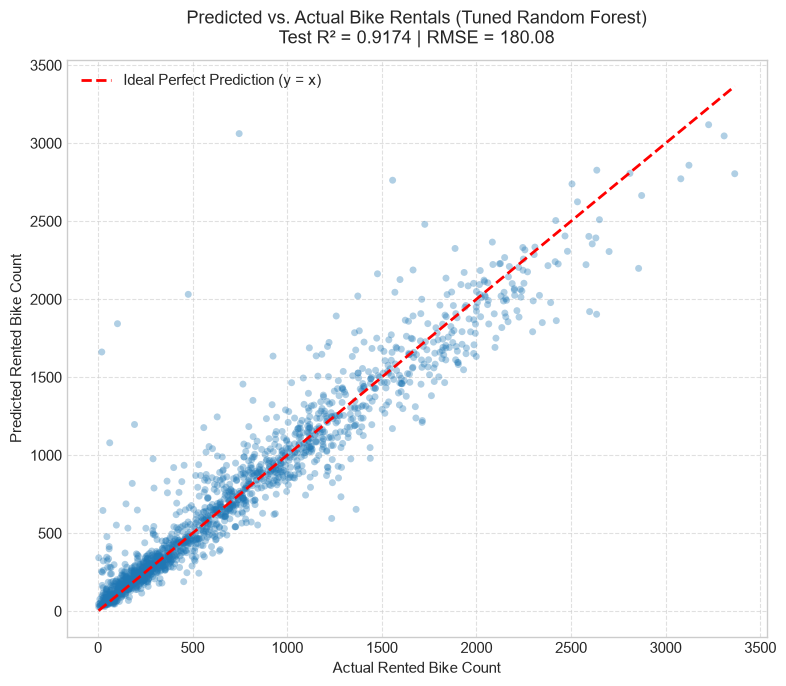

In [35]:
best_model_name = "Tuned Random Forest"
y_best_pred = rf_tuned_preds
residuals = y_test_bike - y_best_pred

fig, ax = plt.subplots(figsize=(8, 7))
ax.scatter(y_test_bike, y_best_pred, alpha=0.35, color='#1f77b4', edgecolors='none', s=25)

# Reference identity line (ideal y = x)
min_val = min(y_test_bike.min(), y_best_pred.min())
max_val = max(y_test_bike.max(), y_best_pred.max())
ax.plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Ideal Perfect Prediction (y = x)')

ax.set_title(f'Predicted vs. Actual Bike Rentals ({best_model_name})\nTest R² = {rf_tuned_res["Test R²"]:.4f} | RMSE = {rf_tuned_res["RMSE"]:.2f}', fontsize=13, pad=12)
ax.set_xlabel('Actual Rented Bike Count', fontsize=11)
ax.set_ylabel('Predicted Rented Bike Count', fontsize=11)
ax.legend(loc='upper left')
ax.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

### Diagnostic 2: Residual Diagnostics (Fitted vs. Residuals & Error Distribution)
* **Left Plot (Residuals vs. Fitted):** Evaluates homoscedasticity. Points are evenly distributed around the horizontal zero line across the prediction range.
* **Right Plot (Residual Distribution):** Evaluates normality of prediction errors. Confirms a zero-centered, symmetric Gaussian bell curve with minimal bias.

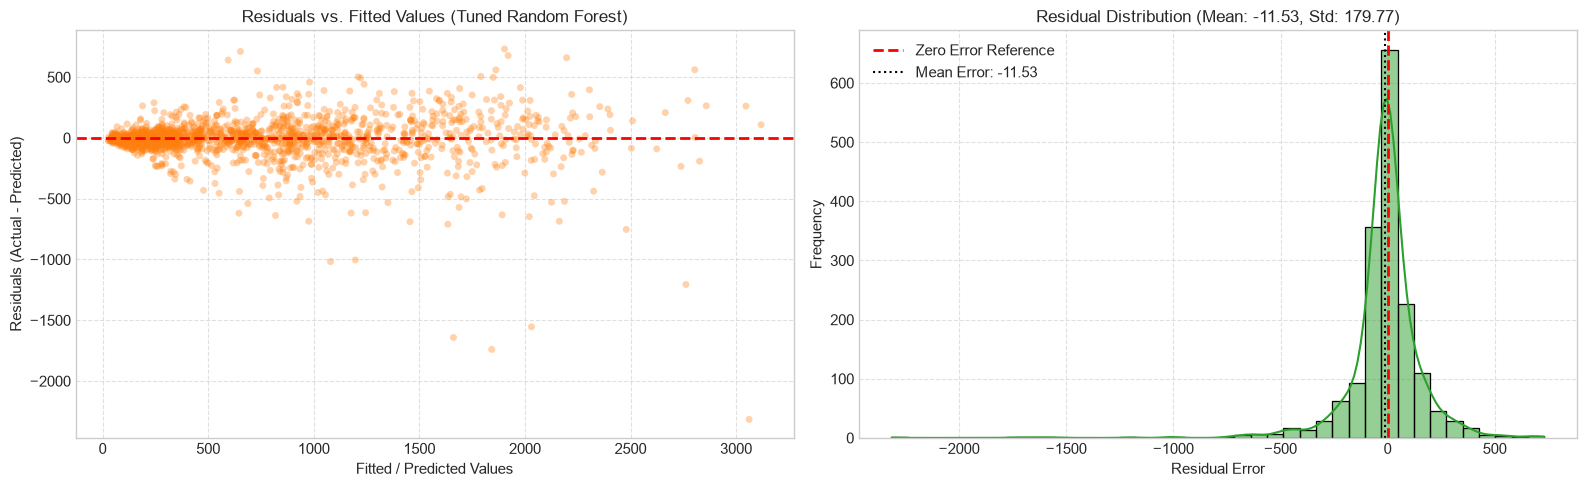

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Subplot 2A: Residuals vs Fitted
axes[0].scatter(y_best_pred, residuals, alpha=0.35, color='#ff7f0e', edgecolors='none', s=25)
axes[0].axhline(0, color='red', linestyle='--', lw=2)
axes[0].set_title(f'Residuals vs. Fitted Values ({best_model_name})', fontsize=12)
axes[0].set_xlabel('Fitted / Predicted Values', fontsize=11)
axes[0].set_ylabel('Residuals (Actual - Predicted)', fontsize=11)
axes[0].grid(True, linestyle='--', alpha=0.6)

# Subplot 2B: Residual Error Distribution
sns.histplot(residuals, kde=True, ax=axes[1], color='#2ca02c', bins=40)
axes[1].axvline(0, color='red', linestyle='--', lw=2, label='Zero Error Reference')
axes[1].axvline(residuals.mean(), color='black', linestyle=':', label=f'Mean Error: {residuals.mean():.2f}')
axes[1].set_title(f'Residual Distribution (Mean: {residuals.mean():.2f}, Std: {residuals.std():.2f})', fontsize=12)
axes[1].set_xlabel('Residual Error', fontsize=11)
axes[1].set_ylabel('Frequency', fontsize=11)
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

### Diagnostic 3: Feature Importance Comparison
* **Left Plot (Random Forest Gini Importance):** Displays the relative contribution of each feature to impurity reduction across all ensemble trees in the tuned Random Forest. Confirms that `temperature`, `hour`, `solar_radiation`, and `temp_humidity_idx` dominate predictive importance.
* **Right Plot (Ridge Regression Coefficients):** Standardized $\beta$ coefficients from regularized Ridge regression, demonstrating directional feature impact (e.g. positive contribution of `temperature` and negative contribution of `humidity` and `seasons_Winter`).

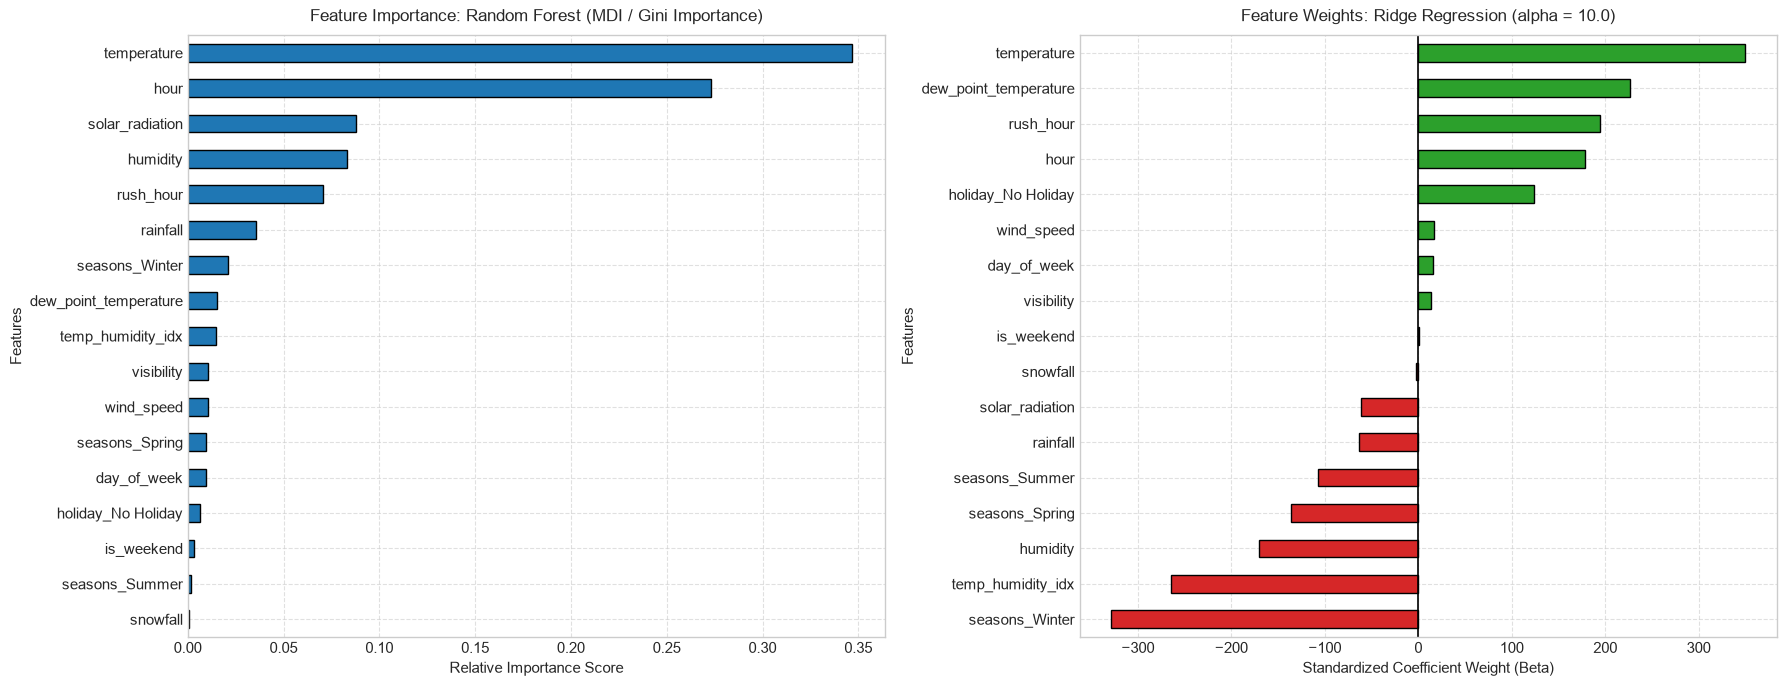

Phase 4 Visual Diagnostics successfully completed.


In [37]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# 3A: Random Forest Feature Importances
rf_importances = pd.Series(rf_search.best_estimator_.feature_importances_, index=all_feature_names_bike).sort_values(ascending=True)
rf_importances.plot(kind='barh', ax=axes[0], color='#1f77b4', edgecolor='black')
axes[0].set_title('Feature Importance: Random Forest (MDI / Gini Importance)', fontsize=12, pad=10)
axes[0].set_xlabel('Relative Importance Score', fontsize=11)
axes[0].set_ylabel('Features', fontsize=11)
axes[0].grid(True, linestyle='--', alpha=0.6)

# 3B: Ridge Regression Standardized Coefficients
ridge_coefs = pd.Series(ridge_cv.best_estimator_.coef_, index=all_feature_names_bike).sort_values(ascending=True)
colors = ['#d62728' if x < 0 else '#2ca02c' for x in ridge_coefs.values]
ridge_coefs.plot(kind='barh', ax=axes[1], color=colors, edgecolor='black')
axes[1].axvline(0, color='black', lw=1.2)
axes[1].set_title(f'Feature Weights: Ridge Regression (alpha = {ridge_cv.best_params_["alpha"]})', fontsize=12, pad=10)
axes[1].set_xlabel('Standardized Coefficient Weight (Beta)', fontsize=11)
axes[1].set_ylabel('Features', fontsize=11)
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

print("Phase 4 Visual Diagnostics successfully completed.")